# Lab 2: Pre-Trained Word Embeddings
**Text classification with a feed-forward neural network and GloVe word embeddings (AG News)**

Christina LaPane, PhDAI-831-B01: Deep Learning and Natural Language Processing

Adapted from Surdeanu & Valenzuela-Escárcega, *Deep Learning for Natural Language Processing: A Gentle Introduction*,
chapter 9 notebook (`chap09_classification.ipynb`, https://github.com/clulab/gentlenlp).

**Before running**

* Packages: `pip install torch numpy pandas scikit-learn nltk gensim tqdm certifi matplotlib`
* AG News files in `data/ag_news_csv/` (`train.csv`, `test.csv`, `classes.txt`), the same folder used in Lab 1.
* GloVe: Step 5 downloads `glove.6B.zip` (822 MB) from Stanford and extracts `glove.6B.300d.txt` into `data/` if it is not already there.
* All figures are also saved to `figures/` for the write-up.

## Step 1: Initialize the code and enable torch, numpy, pandas, and tqdm

In [9]:
import random
import ssl
import certifi
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# enable tqdm in pandas (adds .progress_map / .progress_apply to Series and DataFrames)
tqdm.pandas()

# use a GPU if one is available: CUDA (NVIDIA) or MPS (Apple Silicon); otherwise the CPU
use_gpu = True
if use_gpu and torch.cuda.is_available():
    device = torch.device('cuda')
elif use_gpu and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f'device: {device.type}')

# random seed, so the split, the weight initialization, and dropout are reproducible
seed = 1234
if seed is not None:
    print(f'random seed: {seed}')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# NLTK's tokenizer models must be downloaded once. The certifi line avoids an SSL
# certificate error that python.org builds of Python on macOS often raise.
import nltk
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download('punkt_tab', quiet=True)

device: mps
random seed: 1234


True

## Step 2: Load the training dataset with pandas and take a quick look at the data

In [10]:
from pathlib import Path

data_dir = Path('data/ag_news_csv')
fig_dir = Path('figures')
fig_dir.mkdir(exist_ok=True)

for f in sorted(data_dir.iterdir()):
    print(f'{f.name:12s} {f.stat().st_size/1e6:7.2f} MB')

labels = data_dir.joinpath('classes.txt').read_text().splitlines()
print('classes:', labels)

classes.txt     0.00 MB
test.csv        1.86 MB
train.csv      29.47 MB
classes: ['World', 'Sports', 'Business', 'Sci/Tech']


In [11]:
train_df = pd.read_csv(data_dir / 'train.csv', header=None)
train_df.columns = ['class index', 'title', 'description']
# class indices are 1-based, so subtract 1 to look up the class name in `labels`
train_df.insert(1, 'class', train_df['class index'].map(lambda i: labels[i - 1]))

print(f'rows: {len(train_df):,}  columns: {list(train_df.columns)}')
print('examples per class:')
print(train_df['class'].value_counts().sort_index())
train_df.head()

rows: 120,000  columns: ['class index', 'class', 'title', 'description']
examples per class:
class
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


,class index,class,title,description
0,3,Business,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Business,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Business,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Business,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,Business,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


## Step 3: Replace the backslashes with spaces using the pandas replace() method

In [12]:
print('before:', train_df.loc[0, 'description'])

# join title and description into one lowercased text column (GloVe 6B is lowercased)
train_df['text'] = train_df['title'].str.lower() + ' ' + train_df['description'].str.lower()
train_df['text'] = train_df['text'].str.replace('\\', ' ', regex=False)

print('after: ', train_df.loc[0, 'text'])
print('rows still containing a backslash:', train_df['text'].str.contains('\\', regex=False).sum())

before: Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
after:  wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling band of ultra-cynics, are seeing green again.
rows still containing a backslash: 0


## Step 4: Tokenize the title and description with NLTK's word_tokenize()

In [13]:
from nltk.tokenize import word_tokenize

train_df['tokens'] = train_df['text'].progress_map(word_tokenize)
train_df[['class', 'text', 'tokens']].head()

  0%|          | 0/120000 [00:00<?, ?it/s]

,class,text,tokens
0,Business,wall st. bears claw back into the black (reute...,"[wall, st., bears, claw, back, into, the, blac..."
1,Business,carlyle looks toward commercial aerospace (reu...,"[carlyle, looks, toward, commercial, aerospace..."
2,Business,oil and economy cloud stocks' outlook (reuters...,"[oil, and, economy, cloud, stocks, ', outlook,..."
3,Business,iraq halts oil exports from main southern pipe...,"[iraq, halts, oil, exports, from, main, southe..."
4,Business,"oil prices soar to all-time record, posing new...","[oil, prices, soar, to, all-time, record, ,, p..."


In [14]:
from sklearn.model_selection import train_test_split

# hold out 20% of the training file as a development (validation) set
train_df, dev_df = train_test_split(train_df, train_size=0.8, random_state=seed)
train_df = train_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)
print(f'train rows: {len(train_df):,}')
print(f'dev rows:   {len(dev_df):,}')

train rows: 96,000
dev rows:   24,000


## Step 5: Load the GloVe word embeddings

In [15]:
import urllib.request
import zipfile
from gensim.models import KeyedVectors

glove_path = Path('data/glove.6B.300d.txt')
if not glove_path.exists():
    zip_path = Path('data/glove.6B.zip')
    if not zip_path.exists():
        # nlp.stanford.edu often times out, so try Stanford's file server first, then the Hugging Face copy
        urls = ['https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip',
                'https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip']
        part_path = zip_path.with_suffix('.zip.part')  # rename only when complete, so a failed download isn't reused
        for url in urls:
            try:
                print(f'downloading glove.6B.zip (822 MB) from {url} ...')
                urllib.request.urlretrieve(url, part_path)
                part_path.rename(zip_path)
                break
            except OSError as err:
                print(f'    failed: {err}')
        else:
            raise RuntimeError('could not download GloVe from any mirror')
    with zipfile.ZipFile(zip_path) as z:
        z.extract(glove_path.name, path=glove_path.parent)

# GloVe text files have no word2vec header line, hence no_header=True
glove = KeyedVectors.load_word2vec_format(glove_path, no_header=True)
print('embedding matrix shape:', glove.vectors.shape)
print('dtype:', glove.vectors.dtype)
print('nearest neighbors of "stocks":')
for w, s in glove.most_similar('stocks', topn=5):
    print(f'    {w:12s} {s:.3f}')

downloading glove.6B.zip (822 MB) from https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip ...
embedding matrix shape: (400000, 300)
dtype: float32
nearest neighbors of "stocks":
    stock        0.717
    shares       0.695
    gains        0.644
    investors    0.635
    prices       0.614


## Step 6: Estimate how well the tokenization matches the GloVe vocabulary

In [29]:
from collections import Counter

def count_unknown_words(data, vocabulary):
    """Count every token occurrence that has no GloVe vector."""
    counter = Counter()
    for row in tqdm(data, leave=False):
        counter.update(tok for tok in row if tok not in vocabulary)
    return counter

c = count_unknown_words(train_df['tokens'], glove.key_to_index)

total_tokens = train_df['tokens'].map(len).sum()
unk_tokens = sum(c.values())
all_types = set(train_df['tokens'].explode())
print(f'total number of tokens:            {total_tokens:,}')
print(f'number of unknown tokens:          {unk_tokens:,}')
print(f'percentage of unknown tokens:      {unk_tokens / total_tokens:.2%}')
print(f'distinct tokens (types):           {len(all_types):,}')
print(f'distinct unknown tokens:           {len(c):,}  ({len(c) / len(all_types):.2%} of types)')
print('top 15 unknown tokens:')
for token, n in c.most_common(15):
    print(f'    {n:6,}  {token}')

  0%|          | 0/96000 [00:00<?, ?it/s]

total number of tokens:            4,220,934
number of unknown tokens:          51,230
percentage of unknown tokens:      1.21%
distinct tokens (types):           79,913
distinct unknown tokens:           19,758  (24.72% of types)
top 15 unknown tokens:
     2,389  /b
     1,699  href=
     1,698  /a
     1,456  //www.investor.reuters.com/fullquote.aspx
     1,456  target=/stocks/quickinfo/fullquote
       425  newsfactor
       408  /p
       382  cbs.mw
       353  color=
       342  /font
       341  face=
       341  size=
       341  666666
       196  //www.reuters.co.uk/financequotelookup.jhtml
       196  qtype=sym


## Step 7: Add [UNK] and a zero-initialized [PAD] embedding, then map tokens to IDs

In [30]:
unk_tok = '[UNK]'
pad_tok = '[PAD]'

# [UNK] gets the mean of all GloVe vectors; [PAD] is all zeros
unk_emb = glove.vectors.mean(axis=0)
pad_emb = np.zeros(glove.vector_size, dtype=glove.vectors.dtype)

glove.add_vectors([unk_tok, pad_tok], [unk_emb, pad_emb])
unk_id = glove.key_to_index[unk_tok]
pad_id = glove.key_to_index[pad_tok]

print('embedding matrix shape:', glove.vectors.shape)
print(f'unk_id: {unk_id:,}   pad_id: {pad_id:,}')
print('sum of |[PAD] vector|:', np.abs(glove.vectors[pad_id]).sum())

embedding matrix shape: (400002, 300)
unk_id: 400,000   pad_id: 400,001
sum of |[PAD] vector|: 0.0


In [31]:
def get_id(tok):
    return glove.key_to_index.get(tok, unk_id)

def token_ids(tokens):
    return [get_id(t) for t in tokens]

train_df['token ids'] = train_df['tokens'].progress_map(token_ids)
dev_df['token ids'] = dev_df['tokens'].progress_map(token_ids)

ex = train_df.loc[0]
print(ex['tokens'][:12])
print(ex['token ids'][:12])

  0%|          | 0/96000 [00:00<?, ?it/s]

  0%|          | 0/24000 [00:00<?, ?it/s]

['najaf', "'s", 'residents', 'feel', 'trapped', 'in', 'battle', '(', 'ap', ')', 'ap', '-']
[10709, 9, 1048, 998, 4799, 6, 903, 23, 1582, 24, 1582, 11]


## Step 8: Pad the sequences and get a 2-D NumPy array of token IDs and a 1-D array of gold classes

In [32]:
max_tokens = train_df['token ids'].map(len).max()

def pad_tokens(ids):
    """Truncate to max_tokens, then right-pad with pad_id."""
    ids = ids[:max_tokens]
    return ids + [pad_id] * (max_tokens - len(ids))

def to_arrays(df):
    X = np.array(df['token ids'].map(pad_tokens).tolist(), dtype=np.int64)
    y = (df['class index'] - 1).to_numpy(dtype=np.int64)   # 0-based gold classes
    return X, y

X_train, y_train = to_arrays(train_df)
X_dev, y_dev = to_arrays(dev_df)

lengths = train_df['token ids'].map(len)
print(f'max tokens per article: {max_tokens}  (mean {lengths.mean():.1f}, median {lengths.median():.0f})')
print('X_train:', X_train.shape, X_train.dtype, '  y_train:', y_train.shape, y_train.dtype)
print('X_dev:  ', X_dev.shape, X_dev.dtype, '  y_dev:  ', y_dev.shape, y_dev.dtype)
print(f'share of X_train cells that are padding: {(X_train == pad_id).mean():.1%}')
print('first row (last 5 positions):', X_train[0, -5:], ' gold class:', y_train[0])

max tokens per article: 235  (mean 44.0, median 43)
X_train: (96000, 235) int64   y_train: (96000,) int64
X_dev:   (24000, 235) int64   y_dev:   (24000,) int64
share of X_train cells that are padding: 81.3%
first row (last 5 positions): [400001 400001 400001 400001 400001]  gold class: 0


## Step 9: Construct a PyTorch feed-forward neural network with two layers

In [33]:
from torch import nn

class Model(nn.Module):
    def __init__(self, vectors, pad_id, hidden_dim, output_dim, dropout):
        super().__init__()
        self.pad_id = pad_id
        # frozen pre-trained embedding layer (freeze=True is the default)
        self.embs = nn.Embedding.from_pretrained(torch.as_tensor(vectors), padding_idx=pad_id)
        self.layers = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(vectors.shape[1], hidden_dim),   # layer 1: 300 -> hidden
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim),         # layer 2: hidden -> one logit per class
        )

    def forward(self, x):
        # x: (batch, max_tokens) token IDs
        not_padding = x != self.pad_id
        lengths = not_padding.sum(dim=1, keepdim=True).clamp(min=1)   # real tokens per article
        x = self.embs(x)                     # (batch, max_tokens, 300)
        x = x.sum(dim=1) / lengths           # mean of the real tokens ([PAD] vectors are zero)
        return self.layers(x)

In [34]:
from torch import optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score

# hyperparameters (same as Lab 1 so the two feature types can be compared)
lr = 1e-3
weight_decay = 1e-5
batch_size = 500
shuffle = True
n_epochs = 5
hidden_dim = 50
output_dim = len(labels)
dropout = 0.3

model = Model(glove.vectors, pad_id, hidden_dim, output_dim, dropout).to(device)
loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad],
                       lr=lr, weight_decay=weight_decay)

train_dl = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
                      batch_size=batch_size, shuffle=shuffle)
dev_dl = DataLoader(TensorDataset(torch.from_numpy(X_dev), torch.from_numpy(y_dev)),
                    batch_size=batch_size, shuffle=False)

print(model)
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'parameters: {n_total:,} total, {n_train:,} trainable (embeddings frozen)')
print(f'batches per epoch: train {len(train_dl)}, dev {len(dev_dl)}')

Model(
  (embs): Embedding(400002, 300, padding_idx=400001)
  (layers): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=300, out_features=50, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=50, out_features=4, bias=True)
  )
)
parameters: 120,015,854 total, 15,254 trainable (embeddings frozen)
batches per epoch: train 192, dev 48


## Step 10: Train the model, computing loss and accuracy on the development partition after each epoch

In [35]:
import time

train_loss, train_acc = [], []
dev_loss, dev_acc = [], []
start = time.time()

for epoch in range(n_epochs):
    losses, acc = [], []
    # training mode: dropout is active
    model.train()
    for X, y_true in tqdm(train_dl, desc=f'epoch {epoch+1} (train)', leave=False):
        model.zero_grad()                       # clear gradients from the previous step
        X, y_true = X.to(device), y_true.to(device)
        y_pred = model(X)                       # forward pass: logits
        loss = loss_func(y_pred, y_true)        # cross-entropy loss
        gold = y_true.detach().cpu().numpy()
        pred = np.argmax(y_pred.detach().cpu().numpy(), axis=1)
        losses.append(loss.detach().cpu().item())
        acc.append(accuracy_score(gold, pred))
        loss.backward()                         # back-propagation
        optimizer.step()                        # Adam parameter update
    train_loss.append(np.mean(losses))
    train_acc.append(np.mean(acc))

    # evaluation mode: dropout off, no gradients
    model.eval()
    with torch.no_grad():
        losses, acc = [], []
        for X, y_true in tqdm(dev_dl, desc=f'epoch {epoch+1} (dev)', leave=False):
            X, y_true = X.to(device), y_true.to(device)
            y_pred = model(X)
            loss = loss_func(y_pred, y_true)
            gold = y_true.cpu().numpy()
            pred = np.argmax(y_pred.cpu().numpy(), axis=1)
            losses.append(loss.cpu().item())
            acc.append(accuracy_score(gold, pred))
        dev_loss.append(np.mean(losses))
        dev_acc.append(np.mean(acc))

    print(f'epoch {epoch+1}: train loss {train_loss[-1]:.4f} acc {train_acc[-1]:.4f} | '
          f'dev loss {dev_loss[-1]:.4f} acc {dev_acc[-1]:.4f}')

print(f'training time: {time.time() - start:.0f} s')

epoch 1 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 1 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 1: train loss 0.6819 acc 0.7986 | dev loss 0.3761 acc 0.8783


epoch 2 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 2 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 2: train loss 0.4077 acc 0.8660 | dev loss 0.3340 acc 0.8878


... (5 outputs left out)

epoch 4: train loss 0.3705 acc 0.8759 | dev loss 0.3100 acc 0.8941


epoch 5 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 5 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 5: train loss 0.3625 acc 0.8778 | dev loss 0.3040 acc 0.8942
training time: 18 s


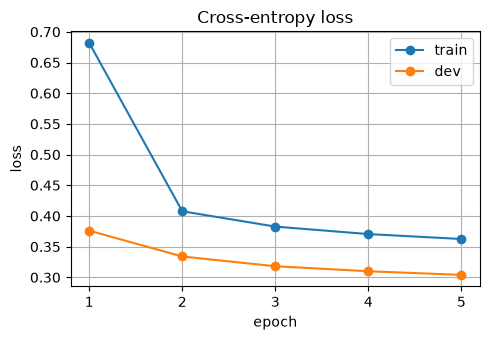

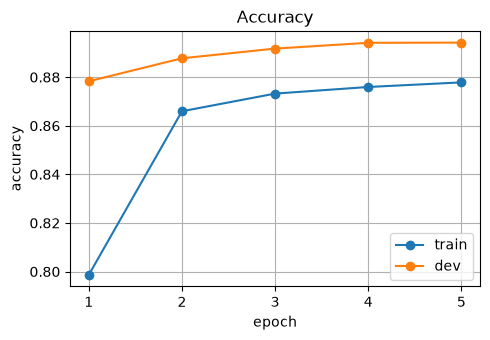

In [36]:
import matplotlib.pyplot as plt

x = np.arange(n_epochs) + 1
for values, ylabel, title, fname in [
        ((train_loss, dev_loss), 'loss', 'Cross-entropy loss', 'figure1_loss.png'),
        ((train_acc, dev_acc), 'accuracy', 'Accuracy', 'figure2_accuracy.png')]:
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.plot(x, values[0], marker='o', label='train')
    ax.plot(x, values[1], marker='o', label='dev')
    ax.set(xlabel='epoch', ylabel=ylabel, title=title)
    ax.grid(True); ax.legend(); ax.set_xticks(x)
    fig.tight_layout()
    fig.savefig(fig_dir / fname, dpi=200)
    plt.show()

## Step 11: Evaluate the model on the testing partition

In [37]:
test_df = pd.read_csv(data_dir / 'test.csv', header=None)
test_df.columns = ['class index', 'title', 'description']
test_df['text'] = test_df['title'].str.lower() + ' ' + test_df['description'].str.lower()
test_df['text'] = test_df['text'].str.replace('\\', ' ', regex=False)
test_df['tokens'] = test_df['text'].progress_map(word_tokenize)
test_df['token ids'] = test_df['tokens'].progress_map(token_ids)
X_test, y_test = to_arrays(test_df)

n_tok = test_df['token ids'].map(len).sum()
n_unk = test_df['token ids'].map(lambda ids: ids.count(unk_id)).sum()
n_trunc = (test_df['token ids'].map(len) > max_tokens).sum()
print(f'test rows: {len(test_df):,}   X_test: {X_test.shape}')
print(f'share of test tokens mapped to [UNK]: {n_unk / n_tok:.2%}')
print(f'test articles longer than max_tokens (truncated): {n_trunc}')

  0%|          | 0/7600 [00:00<?, ?it/s]

  0%|          | 0/7600 [00:00<?, ?it/s]

test rows: 7,600   X_test: (7600, 235)
share of test tokens mapped to [UNK]: 1.15%
test articles longer than max_tokens (truncated): 0


In [38]:
from sklearn.metrics import classification_report

model.eval()
test_dl = DataLoader(TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)),
                     batch_size=batch_size)
y_pred = []
with torch.no_grad():
    for X, _ in tqdm(test_dl, leave=False):
        X = X.to(device)
        y = torch.argmax(model(X), dim=1)       # one predicted class per example
        y_pred.append(y.cpu().numpy())
y_true = y_test
y_pred = np.concatenate(y_pred)

print(f'test accuracy: {accuracy_score(y_true, y_pred):.4f}\n')
print(classification_report(y_true, y_pred, target_names=labels, digits=3))

  0%|          | 0/16 [00:00<?, ?it/s]

test accuracy: 0.8929

              precision    recall  f1-score   support

       World      0.904     0.881     0.892      1900
      Sports      0.951     0.972     0.961      1900
    Business      0.861     0.836     0.848      1900
    Sci/Tech      0.855     0.883     0.869      1900

    accuracy                          0.893      7600
   macro avg      0.893     0.893     0.893      7600
weighted avg      0.893     0.893     0.893      7600



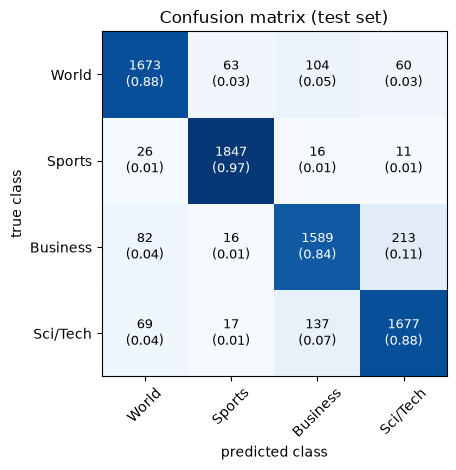

          World  Sports  Business  Sci/Tech
World      1673      63       104        60
Sports       26    1847        16        11
Business     82      16      1589       213
Sci/Tech     69      17       137      1677


In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{cm[i, j]}\n({cm_norm[i, j]:.2f})', ha='center', va='center',
                color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=9)
ax.set_xticks(range(len(labels)), labels, rotation=45)
ax.set_yticks(range(len(labels)), labels)
ax.set(xlabel='predicted class', ylabel='true class', title='Confusion matrix (test set)')
fig.tight_layout()
fig.savefig(fig_dir / 'figure3_confusion_matrix.png', dpi=200)
plt.show()
print(pd.DataFrame(cm, index=labels, columns=labels))

In [40]:
# a few misclassified test examples, to see what kinds of errors the model makes
test_df['pred'] = [labels[i] for i in y_pred]
test_df['gold'] = [labels[i] for i in y_true]
errors = test_df[test_df['pred'] != test_df['gold']]
print(f'misclassified: {len(errors):,} of {len(test_df):,}\n')
for _, r in errors.sample(8, random_state=seed).iterrows():
    print(f'gold={r.gold:9s} pred={r.pred:9s} | {r.title}')

misclassified: 814 of 7,600

gold=Sci/Tech  pred=Business  | TheStreet.com May Be Up for Sale -- Report (Reuters)
gold=Business  pred=Sci/Tech  | Telekom Austria taps the Bulgarian market
gold=World     pred=Sci/Tech  | Sex Toy Shuts Down Australian Airport
gold=World     pred=Sci/Tech  | Kerry to reverse stem cell policy
gold=Business  pred=Sci/Tech  | 34 tech firms sued for alleged LCD patent theft
gold=Business  pred=Sci/Tech  | More buyers choose artificial
gold=Business  pred=Sci/Tech  | Do-not-call bill could be introduced today
gold=Sci/Tech  pred=Business  | Panera Hopes 'Chilling Out' Brews Sales (AP)


In [41]:
# side-by-side with Lab 1 (bag-of-words features, same FFNN and hyperparameters)
from sklearn.metrics import precision_recall_fscore_support

lab1_f1 = {'World': .925, 'Sports': .975, 'Business': .890, 'Sci/Tech': .899}
lab1_acc = .9224
_, _, f1, _ = precision_recall_fscore_support(y_true, y_pred)
comparison = pd.DataFrame({'Lab 1 BoW F1': lab1_f1,
                           'Lab 2 GloVe F1': dict(zip(labels, f1.round(3)))})
comparison.loc['Accuracy'] = [lab1_acc, round(accuracy_score(y_true, y_pred), 4)]
comparison

,Lab 1 BoW F1,Lab 2 GloVe F1
World,0.9250,0.8920
Sports,0.9750,0.9610
Business,0.8900,0.8480
Sci/Tech,0.8990,0.8690
Accuracy,0.9224,0.8929
